*Previous notebook: mini-batch gradient descent and its comparison with batch and stochastic GD. — This notebook: exponentially weighted averages, gradient descent with momentum and Nesterov accelerated gradients.*

### Setup

This notebook builds on **2.1**. The cell below re-runs `2.1_dataset_and_baseline.ipynb` silently to recreate the dataset, the normalised train/val/test splits and the network helpers (`init_params`, `forward`, `backward`, `update_params`, `mse`, `plot_loss`).

In [1]:
%%capture
%run "2.1_dataset_and_baseline.ipynb"

# Exponentially weighted averages

There are optimization algorithms that are better than gradient descent, but you should first learn about Exponentially weighted averages.
If we have data like the temperature of day through the year it could be like this:

t(1) = 40 <br>
t(2) = 49 <br>
t(3) = 45 <br>
... <br>
t(180) = 60 <br>

If we plot this data we will find it some noisy. Now lets compute the Exponentially weighted averages:

V0 = 0 <br>
V1 = 0.9 * V0 + 0.1 * t(1) = 4		# 0.9 and 0.1 are hyperparameters <br>
V2 = 0.9 * V1 + 0.1 * t(2) = 8.5 <br>
V3 = 0.9 * V2 + 0.1 * t(3) = 12.15 <br>

We can implement this algorithm with more accurate results using a moving window. But the code is more efficient and faster using the exponentially weighted averages algorithm. General equation: <br>
$V(t) = \beta * v(t-1) + (1- \beta) * \theta(t)$ <br>

represent averages over ~ $\frac{1} {1 - \beta}$ entries:

$\beta$ = 0.9 will average last 10 entries <br>
$\beta$ = 0.98 will average last 50 entries <br>
$\beta$ = 0.5 will average last 2 entries <br>

**Intuition**: The reason why exponentially weighted averages are useful for further optimizing gradient descent algorithm is that it can give different weights to recent data points (theta) based on value of beta. If beta is high (around 0.9), it smoothens out the averages of skewed data points (oscillations w.r.t. Gradient descent terminology). So this reduces oscillations in gradient descent and hence makes faster and smoother path towerds minima.

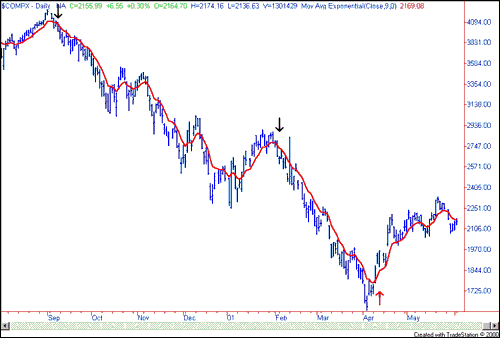

### Bias correction in exponentially weighted averages

The bias correction helps make the exponentially weighted averages more accurate. Because v(0) = 0, the bias of the weighted averages is shifted and the accuracy suffers at the start. To solve the bias issue we have to use this equation: <br>

$v(t) = \frac {\beta v(t-1) + (1- \beta) \theta(t)} {1 - \beta^t}$

As t becomes larger the $(1 - \beta^t)$ becomes close to 1

# Gradient descent with Momentum

The simple idea is to calculate the exponentially weighted averages for your gradients and then update your weights with the new values.
We learned how momentum helps us to reduce oscillations in the gradient steps and attain the convergence faster. The update equation of momentum is given as:

$$v_t = \gamma v_{t-1} + \eta \nabla_\theta J( \theta) $$

Update theta by: 
$${\theta = \theta - v_t } $$

$\gamma$ = 0.9 is very common and works very well in most cases. In practice people don't bother implementing bias correction.


Final train MSE: 0.1201  |  val MSE: 0.0972  |  time: 2.64s


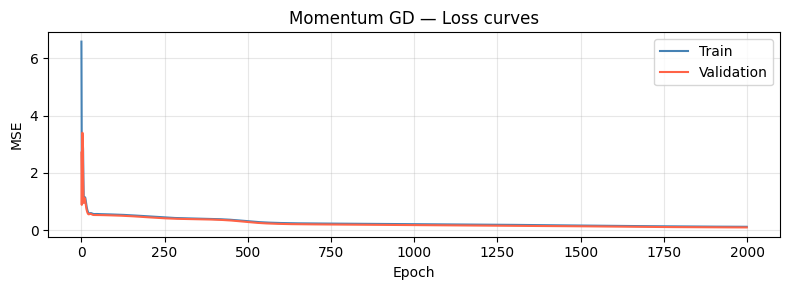

In [2]:
def momentum_gd(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, gamma=0.9, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    vt = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            vt[key]     = gamma * vt[key] + lr * grads['d' + key]
            params[key] = params[key] - vt[key]

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_mom, tl_mom, vl_mom, t_mom = momentum_gd(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, gamma=0.9, epochs=2000
)
plot_loss(tl_mom, vl_mom, title='Momentum GD — Loss curves')

# Nesterov accelerated gradients

Refer the NAG section in the book for the detailed explanation.

The update equation of NAG is given as:

$$v_t = \gamma v_{t-1} + \eta \nabla_\theta J( \theta - \gamma v_{t-1} ) $$

Update theta by:
$${\theta = \theta - v_t } $$

Final train MSE: 0.0557  |  val MSE: 0.0460  |  time: 2.16s


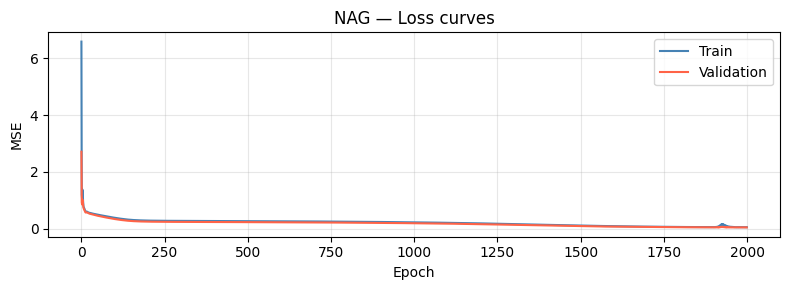

In [3]:
def nag(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, gamma=0.9, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    vt = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for _ in range(epochs):
        # look-ahead: evaluate gradient at the anticipated future position
        params_ahead = {key: params[key] - gamma * vt[key] for key in params}

        y_hat, cache = forward(X_tr, params_ahead)
        grads        = backward(y_tr, y_hat, params_ahead, cache)

        for key in params:
            vt[key]     = gamma * vt[key] + lr * grads['d' + key]
            params[key] = params[key] - vt[key]

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_nag, tl_nag, vl_nag, t_nag = nag(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, gamma=0.9, epochs=2000
)
plot_loss(tl_nag, vl_nag, title='NAG — Loss curves')